Arica Bhuiyan  
Module: Machine Learning & Data Mining  
Notebook: Final Python Notebook 1  

This notebook contains data understanding and preprocessing tasks for the loan dataset.  
The code used in this notebook was reused and adapted from Coursework Code Reuse Session 1 (Week 3) and relevant seminar and tutorial materials.

This section imports the required libraries for data analysis.

Code reused from:
- Coursework Code Reuse Session 1 (Week 3)
- Seminar materials on data exploration

In [1]:
# import pandas for data handling
import pandas as pd

# import numpy for numerical operations
import numpy as np

# import matplotlib for plotting
import matplotlib.pyplot as plt

# import seaborn for visualisation
import seaborn as sns

This code loads the dataset and displays the first rows.

This section loads the dataset and displays the first few rows.

Code reused from:
- Coursework Code Reuse Session 1 (Week 3)

In [2]:
# load dataset
df = pd.read_csv("loan_applications_data.csv")

# display first 10 rows
df.head(10)

/tmp/ipykernel_7835/3586740426.py:2: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("loan_applications_data.csv")


,id,applicant_account_No.,bank_sort_code,age,sex,education_qualifications,income,home_ownership,employment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_loan_amount(allowed),credit_application_acceptance
0,717474,62012825,90025,21.0,M,Unknown,12000.0,OWN,0.0,EDUCATION,15000,6.99,0.12,N,4,Approved,-2426900,0.0
1,211588,3829308,239285,21.0,M,Unknown,13200.0,OWN,2.0,EDUCATION,25000,16.77,0.19,Y,3,Approved,-111739,0.0
2,597607,79622422,300083,23.0,M,Unknown,9600.0,RENT,5.0,MEDICAL,30000,12.42,0.31,N,3,Approved,-89000,0.0
3,684154,86043250,405179,40.0,M,Unknown,182004.0,RENT,3.0,EDUCATION,35000,8.00,0.19,N,11,Approved,35000,0.0
4,343369,73510088,300066,40.0,M,Unknown,90000.0,MORTGAGE,3.0,HOMEIMPROVEMENT,35000,12.42,0.39,N,14,Approved,35000,0.0
5,803527,78040195,608312,40.0,M,Unknown,131004.0,MORTGAGE,9.0,VENTURE,30000,7.90,0.23,N,13,Approved,30000,0.0
6,142876,28963792,236078,40.0,M,Unknown,150000.0,MORTGAGE,9.0,DEBTCONSOLIDATION,25000,11.89,0.17,N,11,Approved,25000,0.0
7,146399,69308685,405047,40.0,M,Unknown,132000.0,MORTGAGE,3.0,HOMEIMPROVEMENT,25000,16.82,0.22,N,17,Approved,25000,0.0
8,593612,56095425,165501,40.0,M,Unknown,80000.0,MORTGAGE,2.0,DEBTCONSOLIDATION,25000,10.25,0.31,N,11,Approved,25000,0.0
9,620220,54207305,700603,40.0,M,Unknown,80000.0,MORTGAGE,9.0,VENTURE,25000,18.67,0.30,N,17,Approved,25000,0.0


This section explores the dataset structure, including data types, missing values and summary statistics.

Code reused from:
- Seminar 1 & 2 (data exploration)

In [3]:
# display dataset information
df.info()

# summary statistics for numerical variables
df.describe()

# dataset shape
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id                             58645 non-null  int64  
 1   applicant_account_No.          58645 non-null  int64  
 2   bank_sort_code                 58645 non-null  int64  
 3   age                            58639 non-null  float64
 4   sex                            362 non-null    object 
 5   education_qualifications       58645 non-null  object 
 6   income                         58614 non-null  float64
 7   home_ownership                 58645 non-null  object 
 8   employment_length              58630 non-null  float64
 9   loan_intent                    58645 non-null  object 
 10  loan_amount                    58645 non-null  int64  
 11  loan_interest_rate             58635 non-null  float64
 12  loan_income_ratio              58645 non-null 

(58645, 18)

This section checks the unique values of the target variable and identifies inconsistencies.

Code reused from:
- Seminar exercises on categorical data exploration

In [14]:
# check values before cleaning
df['loan_approval_status'].unique()

array(['approved', 'declined', 'reject', 'nan', 'accept'], dtype=object)

This cleans the target variable by fixing text formatting.

In [4]:
# convert to string
df['loan_approval_status'] = df['loan_approval_status'].astype(str)

# remove spaces
df['loan_approval_status'] = df['loan_approval_status'].str.strip()

# convert to lowercase
df['loan_approval_status'] = df['loan_approval_status'].str.lower()

# check cleaned values
df['loan_approval_status'].unique()

array(['approved', 'declined', 'reject', 'nan', 'accept'], dtype=object)

This section visualises the distribution of the target variable.

Code reused from:
- Seminar 2/3 on data visualisation

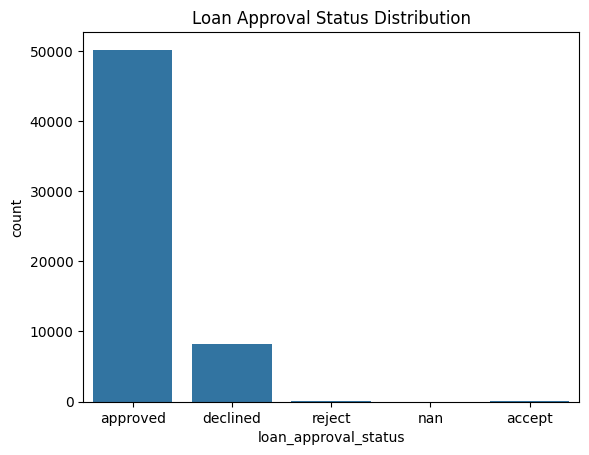

In [5]:
# plot target distribution
sns.countplot(x='loan_approval_status', data=df)

# add title
plt.title("Loan Approval Status Distribution")

# show plot
plt.show()

This section identifies missing values in the dataset.

Code reused from:
- Seminar 2/3 on data cleaning

In [6]:
# check missing values
df.isnull().sum()

,0
id,0
applicant_account_No.,0
bank_sort_code,0
age,6
sex,58283
education_qualifications,0
income,31
home_ownership,0
employment_length,15
loan_intent,0


This section handles missing values by filling numerical columns with the mean.

Code reused from:
- Coursework Code Reuse Session 1 (Week 3)

In [7]:
# fill missing numerical values with mean
df.fillna(df.mean(numeric_only=True), inplace=True)

This section removes columns that do not contribute to prediction.

Code reused from:
- Seminar 3 exercises on feature selection

In [15]:
# check missing values again
df.isnull().sum()

,0
age,0
sex,58283
education_qualifications,0
income,0
home_ownership,0
employment_length,0
loan_intent,0
loan_amount,0
loan_interest_rate,0
loan_income_ratio,0


This removes unnecessary columns.

In [16]:
df.columns

Index(['age', 'sex', 'education_qualifications', 'income', 'home_ownership',
       'employment_length', 'loan_intent', 'loan_amount', 'loan_interest_rate',
       'loan_income_ratio', 'payment_default_on_file', 'credit_history_length',
       'loan_approval_status', 'max_loan_amount(allowed)',
       'credit_application_acceptance'],
      dtype='object')

In [17]:
# dropping identifier columns
df.drop(['id', 'applicant_account_No.', 'bank_sort_code'], axis=1, inplace=True, errors='ignore')

The target variable is separated before encoding to ensure it is not modified.

Code reused from:
- Seminar 1,2,3 on preparing datasets for modelling

In [18]:
df.columns

Index(['age', 'sex', 'education_qualifications', 'income', 'home_ownership',
       'employment_length', 'loan_intent', 'loan_amount', 'loan_interest_rate',
       'loan_income_ratio', 'payment_default_on_file', 'credit_history_length',
       'loan_approval_status', 'max_loan_amount(allowed)',
       'credit_application_acceptance'],
      dtype='object')

This separates the target variable before encoding.

In [9]:
# separate target variable
y_class = df['loan_approval_status']

# remove target from features
X_class = df.drop('loan_approval_status', axis=1)

This section converts categorical variables into numerical values using one hot encoding.

Code reused from:

Coursework Code Reuse Session 1 (Week 3)

In [10]:
# encode categorical variables
X_class = pd.get_dummies(X_class)

# check shape after encoding
X_class.shape

(58645, 33)

This section prepares the final classification dataset.

Code reused from:
- From the seminar exercises

In [19]:
# remove regression column
X_class = X_class.drop('max_loan_amount(allowed)', axis=1, errors='ignore')

# check shapes
X_class.shape, y_class.shape

((58645, 32), (58645,))

This prepares regression dataset for approved loans.

In [11]:
# filter approved loans
df_reg = df[df['loan_approval_status'] == 'approved']

# split features and target
X_reg = df_reg.drop('max_loan_amount(allowed)', axis=1, errors='ignore')
y_reg = df_reg['max_loan_amount(allowed)']

# check shapes
X_reg.shape, y_reg.shape

((50215, 14), (50215,))

In [20]:
# check class distribution
df['loan_approval_status'].value_counts()

,count
loan_approval_status,
approved,50215
declined,8272
accept,79
reject,78
nan,1


In [21]:
# save cleaned dataset
df.to_csv("prepared_loan_applications_data.csv", index=False)

Peer Review

Groupname/ reviewer: Timeout/ Muller Zerufael  
Date: 09/02/26

Tests performed:
- dataset loads correctly
- missing values handled correctly
- encoding applied correctly

Result:
All tests passed and the dataset is ready for modelling.